In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('student_marks_prediction_dataset.csv')

print(df.head())
print("\nDataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

   Study_Hours  Attendance  Marks
0          6.4        64.0   82.3
1          4.1        55.3   61.6
2          7.0        90.4   90.9
3          5.9        84.9   89.8
4          1.7        86.7   60.7

Dataset shape: (50, 3)

Data types:
Study_Hours    float64
Attendance     float64
Marks          float64
dtype: object

Summary statistics:


,Study_Hours,Attendance,Marks
count,50.000000,50.000000,50.000000
mean,4.750000,74.724000,74.656000
std,1.961492,11.704361,12.533549
min,1.300000,55.300000,51.300000
25%,3.225000,64.175000,65.000000
50%,4.600000,75.400000,75.350000
75%,6.400000,84.875000,83.700000
max,7.800000,98.300000,100.000000



Missing values:
Study_Hours    0
Attendance     0
Marks          0
dtype: int64

Duplicate rows: 0


Input features: ['Study_Hours', 'Attendance']
Target: Marks (continuous numerical value)
Rows represent individual synthetic student records.


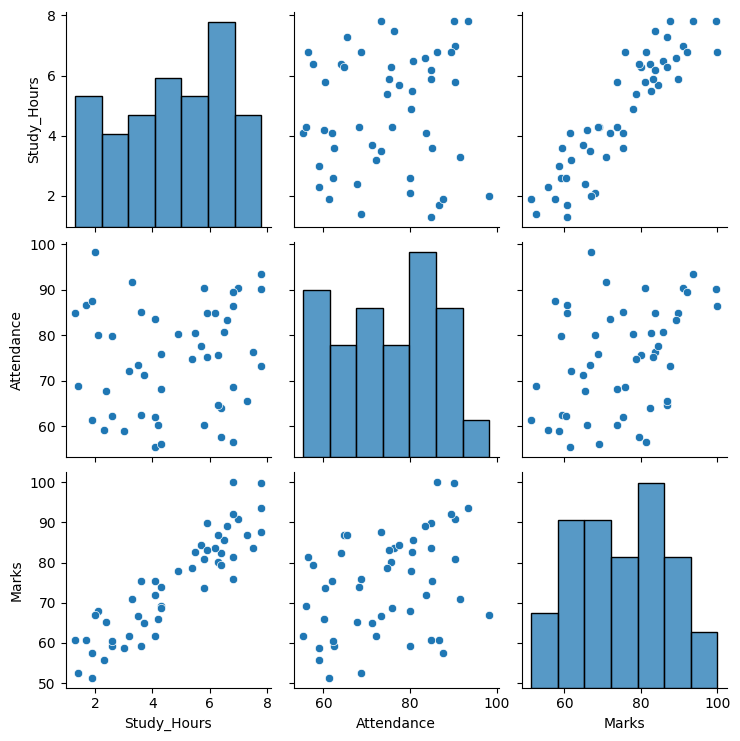

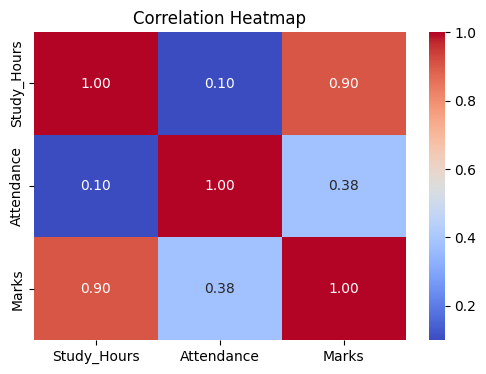

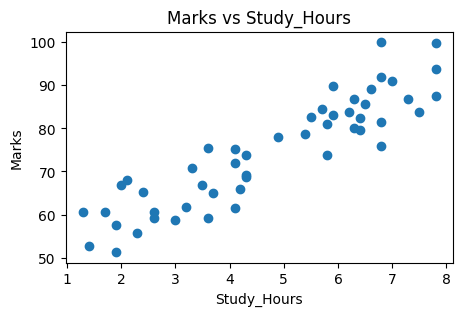

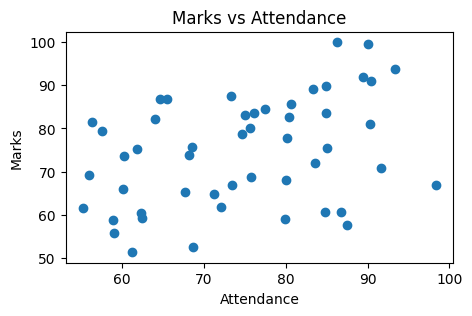

In [11]:
X = df[['Study_Hours', 'Attendance']]
y = df['Marks']

print("Input features:", list(X.columns))
print("Target: Marks (continuous numerical value)")
print("Rows represent individual synthetic student records.")

sns.pairplot(df)
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

for col in X.columns:
    plt.figure(figsize=(5, 3))
    plt.scatter(df[col], y)
    plt.xlabel(col)
    plt.ylabel('Marks')
    plt.title(f'Marks vs {col}')
    plt.show()

In [15]:
sample = df[['Study_Hours', 'Attendance', 'Marks']].head(6).copy()
display(sample)

X_manual = np.column_stack((
    np.ones(len(sample)),
    sample[['Study_Hours', 'Attendance']].values
))

y_manual = sample['Marks'].values.reshape(-1, 1)

XtX = X_manual.T @ X_manual
Xty = X_manual.T @ y_manual

beta_manual = np.linalg.solve(XtX, Xty)

print("X transpose X:\n", XtX)
print("\nX transpose y:\n", Xty)
print("\nManual coefficients [b0, b1, b2]:", beta_manual.ravel())

manual_check = LinearRegression()
manual_check.fit(
    sample[['Study_Hours', 'Attendance']],
    sample['Marks']
)

print("\nLibrary intercept:", manual_check.intercept_)
print("Library coefficients:", manual_check.coef_)

manual_pred = float(X_manual[0] @ beta_manual.ravel())
manual_residual = float(y_manual[0, 0] - manual_pred)

print("First-row manual prediction:", round(manual_pred, 2))
print("First-row residual (actual - predicted):", round(manual_residual, 2))

,Study_Hours,Attendance,Marks
0,6.4,64.0,82.3
1,4.1,55.3,61.6
2,7.0,90.4,90.9
3,5.9,84.9,89.8
4,1.7,86.7,60.7
5,7.8,90.1,99.7


X transpose X:
 [[6.000000e+00 3.290000e+01 4.714000e+02]
 [3.290000e+01 2.053100e+02 2.620210e+03]
 [4.714000e+02 2.620210e+03 3.816916e+04]]

X transpose y:
 [[  485.  ]
 [ 2826.25]
 [38760.72]]

Manual coefficients [b0, b1, b2]: [16.71222598  6.1483599   0.38702928]

Library intercept: 16.712225979773947
Library coefficients: [6.1483599  0.38702928]
First-row manual prediction: 80.83
First-row residual (actual - predicted): 1.47


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

correlations = (
    X_train.join(y_train)
    .corr(numeric_only=True)['Marks']
    .drop('Marks')
    .abs()
)

best_feature = correlations.idxmax()

print("Selected single feature:", best_feature)

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)

single_pred = single_model.predict(X_test[[best_feature]])

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

multi_pred = multi_model.predict(X_test)

print("\nSingle-feature intercept:", single_model.intercept_)
print("Single-feature coefficient:", dict(zip([best_feature], single_model.coef_)))

print("Multiple-feature intercept:", multi_model.intercept_)
print("Multiple-feature coefficients:", dict(zip(X.columns, multi_model.coef_)))

Training rows: 40
Testing rows: 10
Selected single feature: Study_Hours

Single-feature intercept: 47.04719831422106
Single-feature coefficient: {'Study_Hours': np.float64(5.731076305016654)}
Multiple-feature intercept: 24.0480167164462
Multiple-feature coefficients: {'Study_Hours': np.float64(5.634234246985946), 'Attendance': np.float64(0.3159568045368768)}


In [20]:
print("Regression Equation:")
print(f"Marks = {multi_model.intercept_:.2f} + "
      f"{multi_model.coef_[0]:.2f} * Study_Hours + "
      f"{multi_model.coef_[1]:.2f} * Attendance")

print("\nCoefficient Interpretation:")
print("Study Hours coefficient:", round(multi_model.coef_[0], 2))
print("Attendance coefficient:", round(multi_model.coef_[1], 2))

Regression Equation:
Marks = 24.05 + 5.63 * Study_Hours + 0.32 * Attendance

Coefficient Interpretation:
Study Hours coefficient: 5.63
Attendance coefficient: 0.32


In [21]:
mae = mean_absolute_error(y_test, multi_pred)
mse = mean_squared_error(y_test, multi_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, multi_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

MAE: 2.36
MSE: 8.58
RMSE: 2.93
R2 Score: 0.93


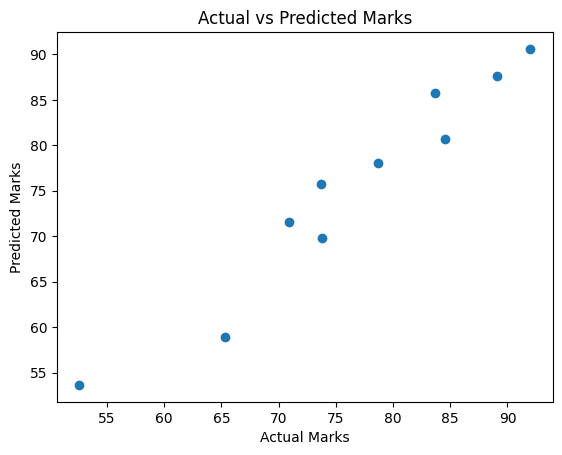

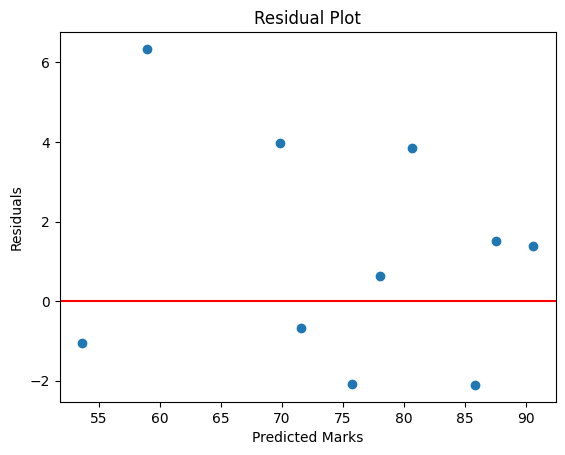

In [22]:
plt.scatter(y_test, multi_pred)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.show()

# Residual plot
residuals = y_test - multi_pred

plt.scatter(multi_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

Feature Correlation:
             Study_Hours  Attendance
Study_Hours     1.000000    0.099498
Attendance      0.099498    1.000000


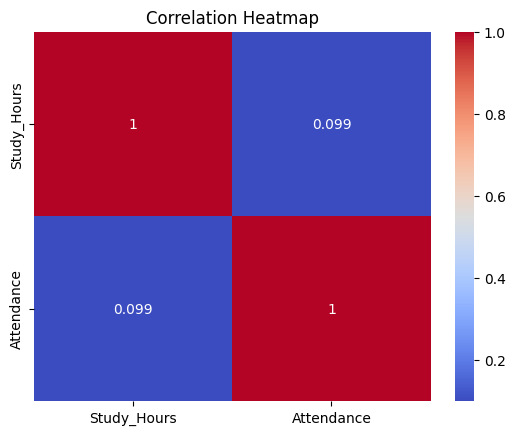

In [23]:
print("Feature Correlation:")
print(X.corr())

sns.heatmap(X.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [24]:
new_student = pd.DataFrame({
    'Study_Hours': [5],
    'Attendance': [85]
})

prediction = multi_model.predict(new_student)

print("Predicted Marks:", round(prediction[0], 2))

print("\nConclusion:")
print("The model predicts student marks using study hours and attendance.")

Predicted Marks: 79.08

Conclusion:
The model predicts student marks using study hours and attendance.
